In [1]:
# Bank Customer Churn Analysis (pandas + matplotlib, no ML)
# Dataset: Churn_Modelling.csv (Kaggle: "Churn Modelling" / "Bank Customer Churn")
# Columns: RowNumber, CustomerId, Surname, CreditScore, Geography, Gender, Age,
#          Tenure, Balance, NumOfProducts, HasCrCard, IsActiveMember,
#          EstimatedSalary, Exited (1 = churned)
 
# %% 1. Load and inspect
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
 
sns.set_theme(style="whitegrid")
os.makedirs("charts", exist_ok=True)
 
df = pd.read_csv("c:\\Users\\SYED  MOHAMMED GHOUS\\OneDrive\\Documents\\Churn Modelling.csv")
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print("Duplicate customers:", df["CustomerId"].duplicated().sum())

(10000, 14)
RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
Duplicate customers: 0


In [ ]:
# %% 2. Clean and feature engineering
df = df.drop(columns=["RowNumber", "Surname"])
df = df.drop_duplicates(subset="CustomerId")
 

 
 

In [10]:
df["Churn"] = df["Exited"].map({1: "Churned", 0: "Retained"})
 


In [13]:
df["AgeGroup"] = pd.cut(
    df["Age"], bins=[17, 30, 40, 50, 60, 100],
    labels=["18-30", "31-40", "41-50", "51-60", "60+"])


In [15]:
df["TenureBand"] = pd.cut(
    df["Tenure"], bins=[-1, 1, 3, 6, 10],
    labels=["0-1 yrs", "2-3 yrs", "4-6 yrs", "7-10 yrs"])


In [17]:
df["CreditBand"] = pd.cut(
    df["CreditScore"], bins=[0, 579, 669, 739, 799, 900],
    labels=["Poor", "Fair", "Good", "Very Good", "Excellent"])


In [20]:
df["BalanceBand"] = np.where(df["Balance"] == 0, "Zero balance", "Has balance")


In [22]:
df["SalaryBand"] = pd.qcut(
    df["EstimatedSalary"], 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
 

In [24]:

overall = df["Exited"].mean()
print(f"Overall churn rate: {overall:.1%}")

Overall churn rate: 20.4%


In [28]:
def churn_by(col):
    t = (df.groupby(col, observed=True)["Exited"]
           .agg(customers="count", churned="sum", churn_rate="mean")
           .reset_index())
    t["churn_rate"] = (t["churn_rate"] * 100).round(1)
    return t
print(t := churn_by("Geography"))

  Geography  customers  churned  churn_rate
0    France       5014      810        16.2
1   Germany       2509      814        32.4
2     Spain       2477      413        16.7


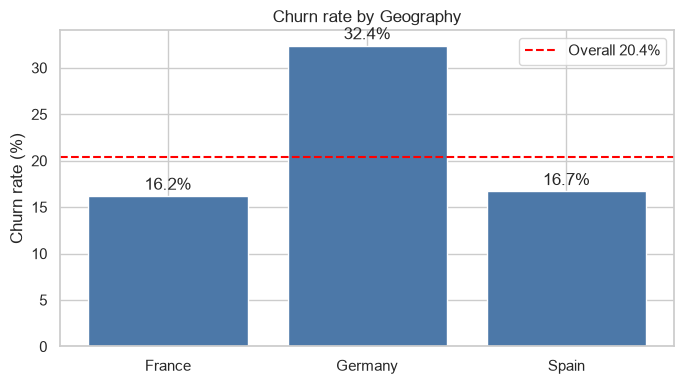

  Geography  customers  churned  churn_rate
0    France       5014      810        16.2
1   Germany       2509      814        32.4
2     Spain       2477      413        16.7


In [31]:
def plot_churn_by(col, title=None, order=None):
    t = churn_by(col)
    if order:
        t = t.set_index(col).loc[order].reset_index()
    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(t[col].astype(str), t["churn_rate"], color="#4C78A8")
    ax.axhline(overall * 100, color="red", ls="--", label=f"Overall {overall:.1%}")
    ax.bar_label(bars, fmt="%.1f%%", padding=2)
    ax.set_ylabel("Churn rate (%)")
    ax.set_title(title or f"Churn rate by {col}")
    ax.legend()
    plt.tight_layout()
    plt.savefig(f"charts/churn_by_{col}.png", dpi=150)
    plt.show()
    return t
print(plot_churn_by("Geography", order=["France", "Germany", "Spain"]))

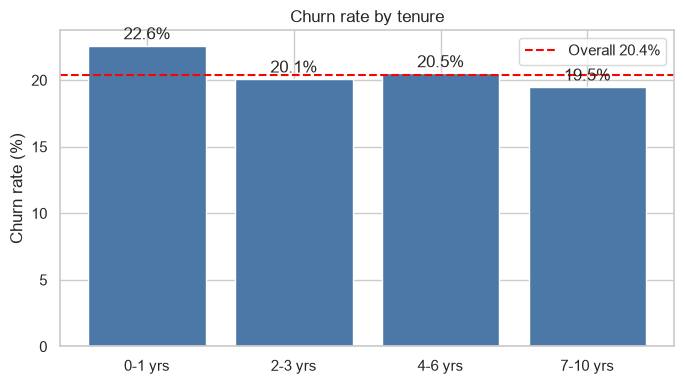

  TenureBand  customers  churned  churn_rate
0    0-1 yrs       1448      327        22.6
1    2-3 yrs       2057      414        20.1
2    4-6 yrs       2968      608        20.5
3   7-10 yrs       3527      688        19.5
    Tenure  customers  churned  churn_rate
0        0        413       95        23.0
1        1       1035      232        22.4
2        2       1048      201        19.2
3        3       1009      213        21.1
4        4        989      203        20.5
5        5       1012      209        20.7
6        6        967      196        20.3
7        7       1028      177        17.2
8        8       1025      197        19.2
9        9        984      213        21.6
10      10        490      101        20.6


In [33]:
# %% 4. Bucket 1: Time-based patterns (tenure)
print(plot_churn_by("TenureBand", "Churn rate by tenure"))
print(churn_by("Tenure"))  # year-by-year view

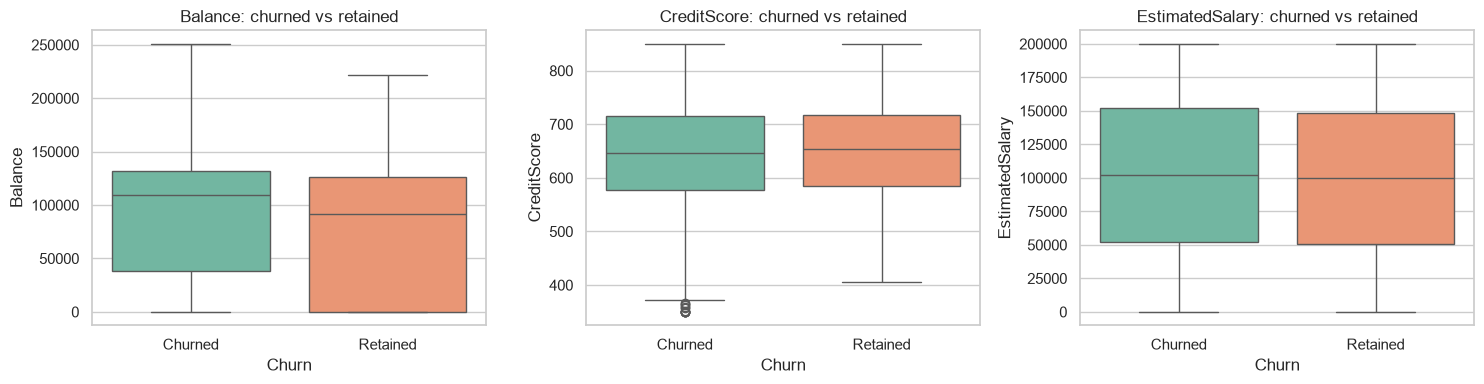

          Balance           CreditScore        EstimatedSalary            \
             mean    median        mean median            mean    median   
Churn                                                                      
Churned   91109.0  109349.0       645.0  646.0        101466.0  102461.0   
Retained  72745.0   92073.0       652.0  653.0         99738.0   99645.0   

           Age         
          mean median  
Churn                  
Churned   45.0   45.0  
Retained  37.0   36.0  


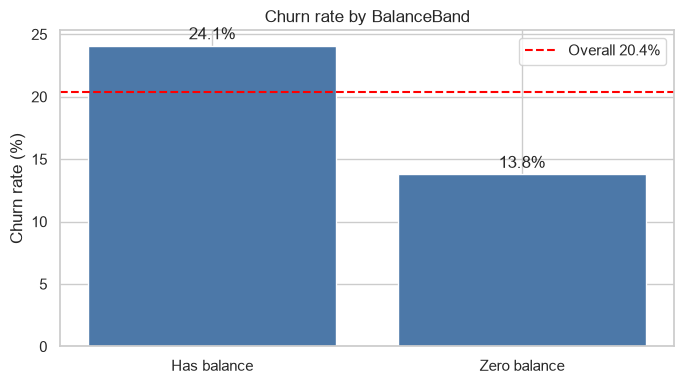

    BalanceBand  customers  churned  churn_rate
0   Has balance       6383     1537        24.1
1  Zero balance       3617      500        13.8


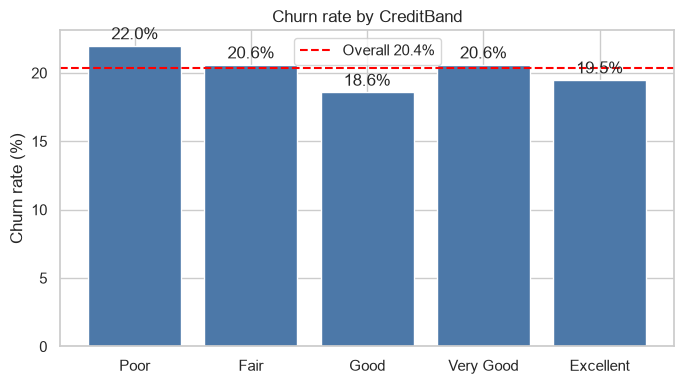

  CreditBand  customers  churned  churn_rate
0       Poor       2362      520        22.0
1       Fair       3331      685        20.6
2       Good       2428      452        18.6
3  Very Good       1224      252        20.6
4  Excellent        655      128        19.5


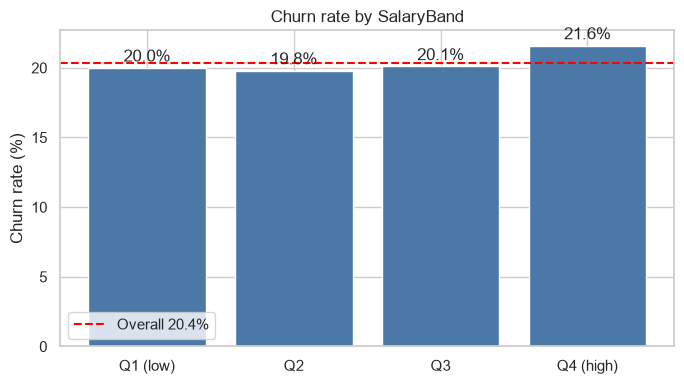

  SalaryBand  customers  churned  churn_rate
0   Q1 (low)       2500      500        20.0
1         Q2       2500      495        19.8
2         Q3       2500      503        20.1
3  Q4 (high)       2500      539        21.6


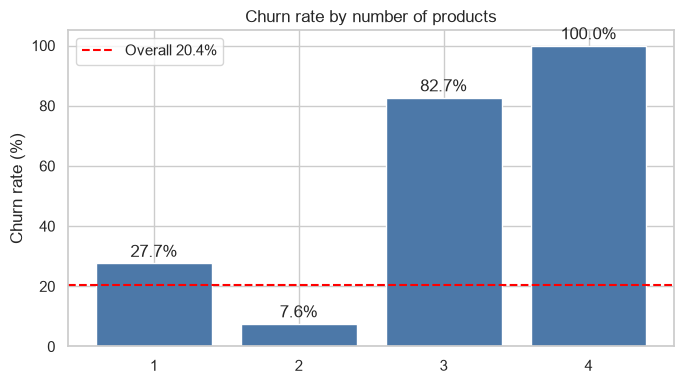

   NumOfProducts  customers  churned  churn_rate
0              1       5084     1409        27.7
1              2       4590      348         7.6
2              3        266      220        82.7
3              4         60       60       100.0


In [36]:
# %% 5. Bucket 2: Amount / usage distributions
# Balance, credit score, salary, products
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Balance", "CreditScore", "EstimatedSalary"]):
    sns.boxplot(data=df, x="Churn", y=col, hue="Churn", palette="Set2", legend=False, ax=ax)
    ax.set_title(f"{col}: churned vs retained")
plt.tight_layout()
plt.savefig("charts/distributions_boxplots.png", dpi=150)
plt.show()
 
print(df.groupby("Churn")[["Balance", "CreditScore", "EstimatedSalary", "Age"]]
        .agg(["mean", "median"]).round(0))
 
print(plot_churn_by("BalanceBand"))
print(plot_churn_by("CreditBand"))
print(plot_churn_by("SalaryBand"))
print(plot_churn_by("NumOfProducts", "Churn rate by number of products"))
 

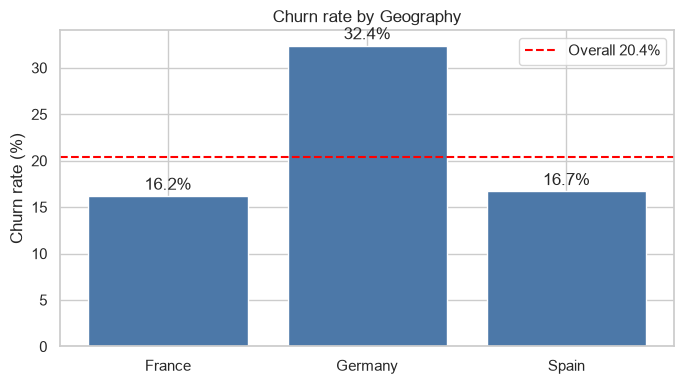

  Geography  customers  churned  churn_rate
0    France       5014      810        16.2
1   Germany       2509      814        32.4
2     Spain       2477      413        16.7


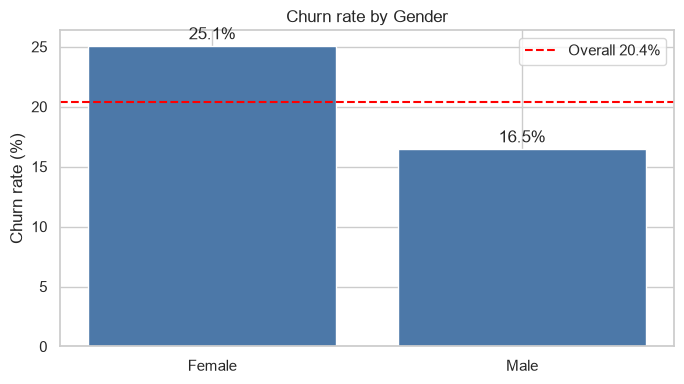

   Gender  customers  churned  churn_rate
0  Female       4543     1139        25.1
1    Male       5457      898        16.5


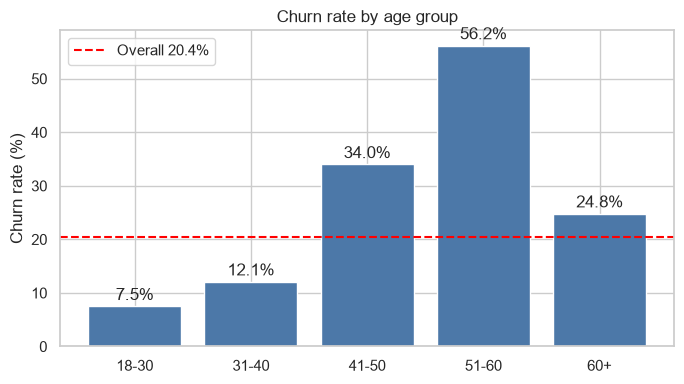

  AgeGroup  customers  churned  churn_rate
0    18-30       1968      148         7.5
1    31-40       4451      538        12.1
2    41-50       2320      788        34.0
3    51-60        797      448        56.2
4      60+        464      115        24.8


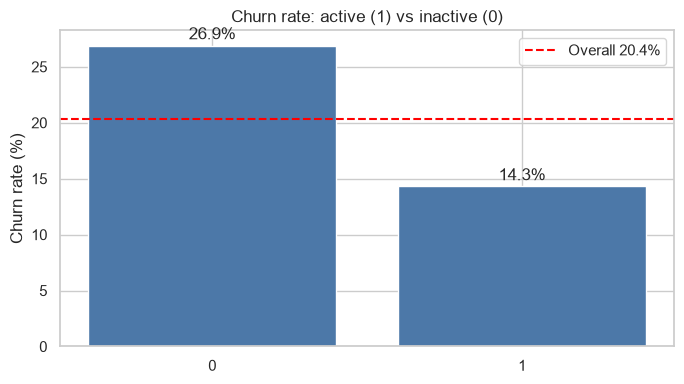

   IsActiveMember  customers  churned  churn_rate
0               0       4849     1302        26.9
1               1       5151      735        14.3


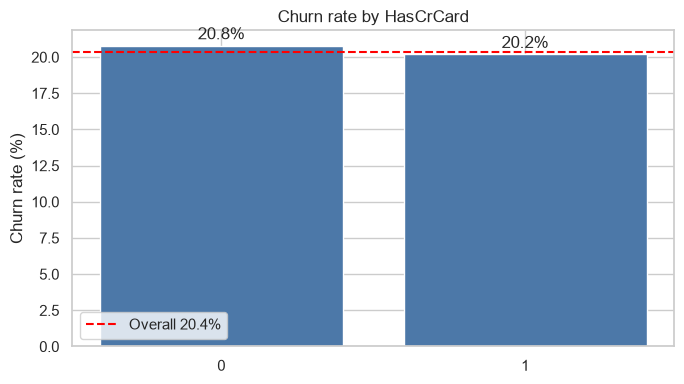

   HasCrCard  customers  churned  churn_rate
0          0       2945      613        20.8
1          1       7055     1424        20.2


In [38]:
print(plot_churn_by("Geography"))
print(plot_churn_by("Gender"))
print(plot_churn_by("AgeGroup", "Churn rate by age group"))
print(plot_churn_by("IsActiveMember", "Churn rate: active (1) vs inactive (0)"))
print(plot_churn_by("HasCrCard"))

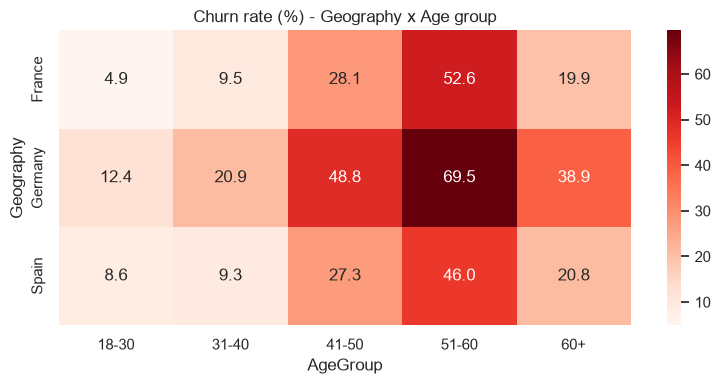

In [40]:
pivot = df.pivot_table(index="Geography", columns="AgeGroup",
                       values="Exited", aggfunc="mean", observed=True) * 100
plt.figure(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds")
plt.title("Churn rate (%) - Geography x Age group")
plt.tight_layout()
plt.savefig("charts/heatmap_geo_age.png", dpi=150)
plt.show()

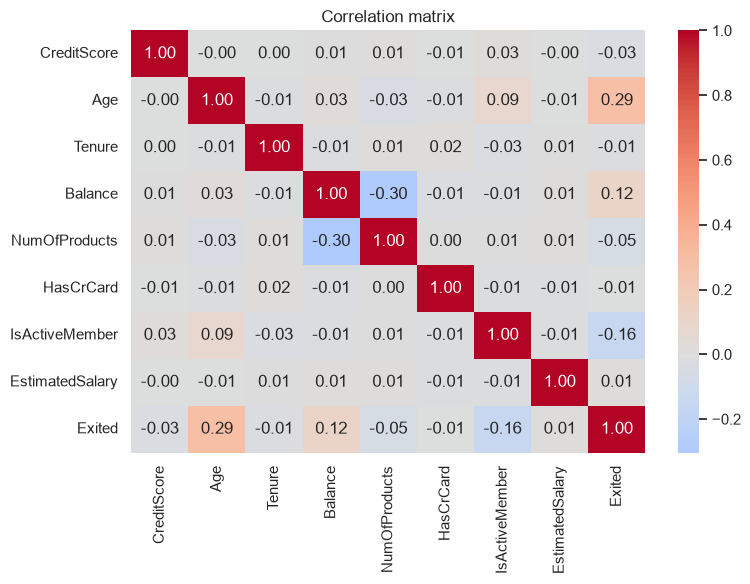

In [42]:
# %% 8. Correlation heatmap (numeric only)
num = df[["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
          "HasCrCard", "IsActiveMember", "EstimatedSalary", "Exited"]]
plt.figure(figsize=(8, 6))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig("charts/correlation.png", dpi=150)
plt.show()

In [43]:
# %% 9. Rule-based early-warning flag (the "alert triggers", no ML)
# Adjust thresholds after looking at your own results above.
# Weighted points: bigger gaps in the charts get more points.
# Gender is deliberately NOT used as a trigger.
#   Age 41-50            -> 2 points   (churn 34.0%)
#   Age 51-60            -> 3 points   (churn 56.2%)
#   Germany              -> 2 points   (churn 32.4% vs ~16% elsewhere)
#   3 or 4 products      -> 3 points   (churn 82.7% / 100%, small group)
#   1 product            -> 1 point    (churn 27.7%)
#   Inactive member      -> 2 points   (26.9% vs 14.3% for active members)
#   Germany AND age 41-60-> +1 bonus   (heatmap: 48.8% to 69.5%)
df["Pts_Age"] = np.select(
    [df["Age"].between(51, 60), df["Age"].between(41, 50)], [3, 2], default=0)

 

In [44]:
df["Pts_Germany"] = (df["Geography"] == "Germany").astype(int) * 2


In [45]:
df["Pts_Products"] = np.select(
    [df["NumOfProducts"] >= 3, df["NumOfProducts"] == 1], [3, 1], default=0)


In [46]:
df["Pts_Inactive"] = (df["IsActiveMember"] == 0).astype(int) * 2


In [47]:
df["Pts_Combo"] = ((df["Geography"] == "Germany")
                   & df["Age"].between(41, 60)).astype(int)
 


In [48]:
df["RiskScore"] = (df["Pts_Age"] + df["Pts_Germany"] + df["Pts_Products"]
                   + df["Pts_Inactive"] + df["Pts_Combo"])
 


In [49]:
# Max score = 3 + 2 + 3 + 2 + 1 = 11
df["RiskTier"] = pd.cut(df["RiskScore"], bins=[-1, 2, 4, 11],
                        labels=["Low", "Medium", "High"])
 


In [50]:
# Does churn rise with the score? It should, if the rules work.
print(churn_by("RiskScore"))
print(churn_by("RiskTier"))
 


    RiskScore  customers  churned  churn_rate
0           0       1381       38         2.8
1           1       1344      117         8.7
2           2       2049      113         5.5
3           3       2173      429        19.7
4           4        871      150        17.2
5           5       1129      474        42.0
6           6        356      234        65.7
7           7        262      137        52.3
8           8        300      220        73.3
9           9         96       88        91.7
10         10         23       21        91.3
11         11         16       16       100.0
  RiskTier  customers  churned  churn_rate
0      Low       4774      268         5.6
1   Medium       3044      579        19.0
2     High       2182     1190        54.5


In [51]:
# Share of all churners caught by the High tier (how useful the watchlist is)
high = df[df["RiskTier"] == "High"]
print(f"High tier: {len(high)} customers ({len(high)/len(df):.1%} of all), "
      f"capturing {high['Exited'].sum()/df['Exited'].sum():.1%} of all churners")
 


High tier: 2182 customers (21.8% of all), capturing 58.4% of all churners


In [53]:
# How much balance sits with high-risk customers (revenue at risk)
at_risk = df[df["RiskTier"] == "High"]
print("High-risk customers:", len(at_risk))
print("Balance at risk:", f"{at_risk['Balance'].sum():,.0f}")

High-risk customers: 2182
Balance at risk: 227,054,520


In [18]:
df.to_csv("bank_churn_clean.csv", index=False)
print("Saved bank_churn_clean.csv")

Saved bank_churn_clean.csv


In [57]:
print(df[["CreditScore", "Age", "Tenure", "Balance",
          "NumOfProducts", "EstimatedSalary"]].describe().round(1))

       CreditScore      Age   Tenure   Balance  NumOfProducts  EstimatedSalary
count      10000.0  10000.0  10000.0   10000.0        10000.0          10000.0
mean         650.5     38.9      5.0   76485.9            1.5         100090.2
std           96.7     10.5      2.9   62397.4            0.6          57510.5
min          350.0     18.0      0.0       0.0            1.0             11.6
25%          584.0     32.0      3.0       0.0            1.0          51002.1
50%          652.0     37.0      5.0   97198.5            1.0         100193.9
75%          718.0     44.0      7.0  127644.2            2.0         149388.2
max          850.0     92.0     10.0  250898.1            4.0         199992.5


Churn
Retained    7963
Churned     2037
Name: count, dtype: int64


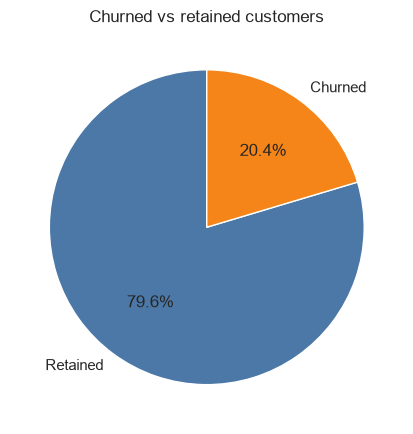

In [59]:
counts = df["Churn"].value_counts()
print(counts)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.pie(counts, labels=counts.index, autopct="%1.1f%%",
       colors=["#4C78A8", "#F58518"], startangle=90)
ax.set_title("Churned vs retained customers")
plt.tight_layout()
plt.savefig("charts/eda_churn_split.png", dpi=150)
plt.show()

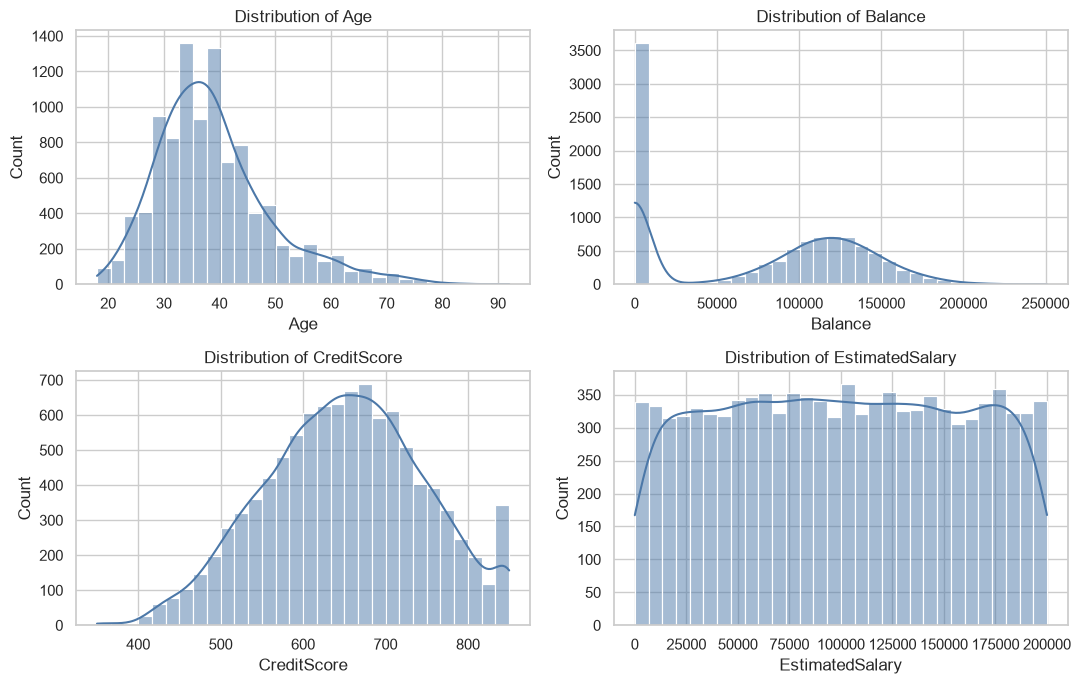

In [61]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ["Age", "Balance", "CreditScore", "EstimatedSalary"]):
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color="#4C78A8")
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.savefig("charts/eda_histograms.png", dpi=150)
plt.show()

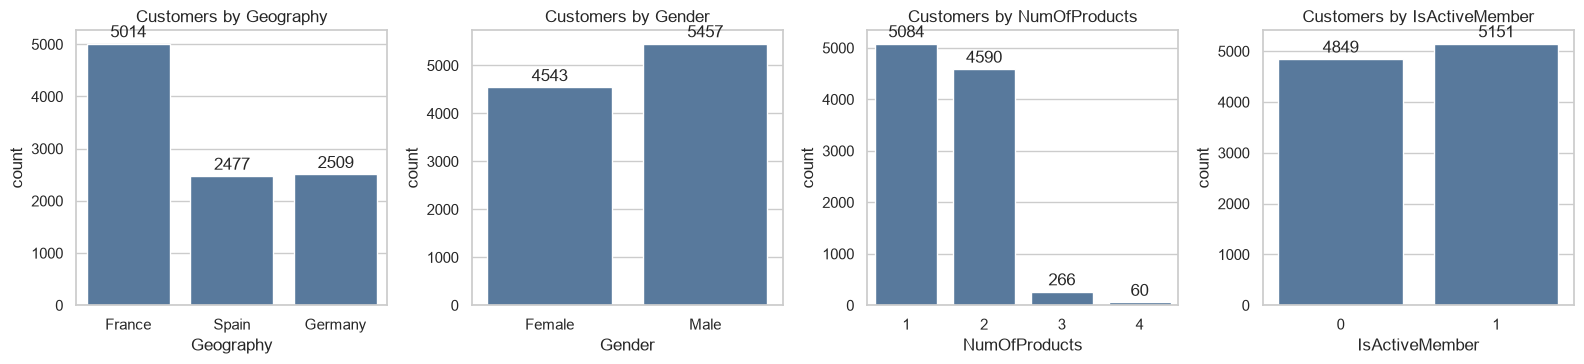

In [63]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, col in zip(axes, ["Geography", "Gender", "NumOfProducts", "IsActiveMember"]):
    sns.countplot(data=df, x=col, ax=ax, color="#4C78A8")
    ax.set_title(f"Customers by {col}")
    ax.bar_label(ax.containers[0], padding=2)
plt.tight_layout()
plt.savefig("charts/eda_countplots.png", dpi=150)
plt.show()

In [65]:
# (v) Data quality notes
print("Missing values per column:\n", df.isna().sum())
zero_bal = (df["Balance"] == 0).mean()
print(f"Customers with zero balance: {zero_bal:.1%}")
 

Missing values per column:
 CustomerId         0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
Churn              0
AgeGroup           0
TenureBand         0
CreditBand         0
BalanceBand        0
SalaryBand         0
Pts_Age            0
Pts_Germany        0
Pts_Products       0
Pts_Inactive       0
Pts_Combo          0
RiskScore          0
RiskTier           0
dtype: int64
Customers with zero balance: 36.2%


In [7]:

# Fix missing AgeGroup and TenureBand columns

# Make sure the source columns exist
required = ["Age", "Tenure"]

missing = [col for col in required if col not in df.columns]

if missing:
    raise KeyError(
        f"Missing source columns: {missing}. "
        f"Available columns: {df.columns.tolist()}"
    )

# Create age categories
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[17, 30, 40, 50, 60, float("inf")],
    labels=["18-30", "31-40", "41-50", "51-60", "60+"],
    include_lowest=True
)

# Create tenure categories
df["TenureBand"] = pd.cut(
    df["Tenure"],
    bins=[-1, 1, 3, 6, 10],
    labels=["0-1 yrs", "2-3 yrs", "4-6 yrs", "7-10 yrs"]
)

# Confirm both columns were created
print("AgeGroup created:", "AgeGroup" in df.columns)
print("TenureBand created:", "TenureBand" in df.columns)

print("\nAge groups:")
print(df["AgeGroup"].value_counts(sort=False))

print("\nTenure groups:")
print(df["TenureBand"].value_counts(sort=False))


AgeGroup created: True
TenureBand created: True

Age groups:
AgeGroup
18-30    1968
31-40    4451
41-50    2320
51-60     797
60+       464
Name: count, dtype: int64

Tenure groups:
TenureBand
0-1 yrs     1448
2-3 yrs     2057
4-6 yrs     2968
7-10 yrs    3527
Name: count, dtype: int64


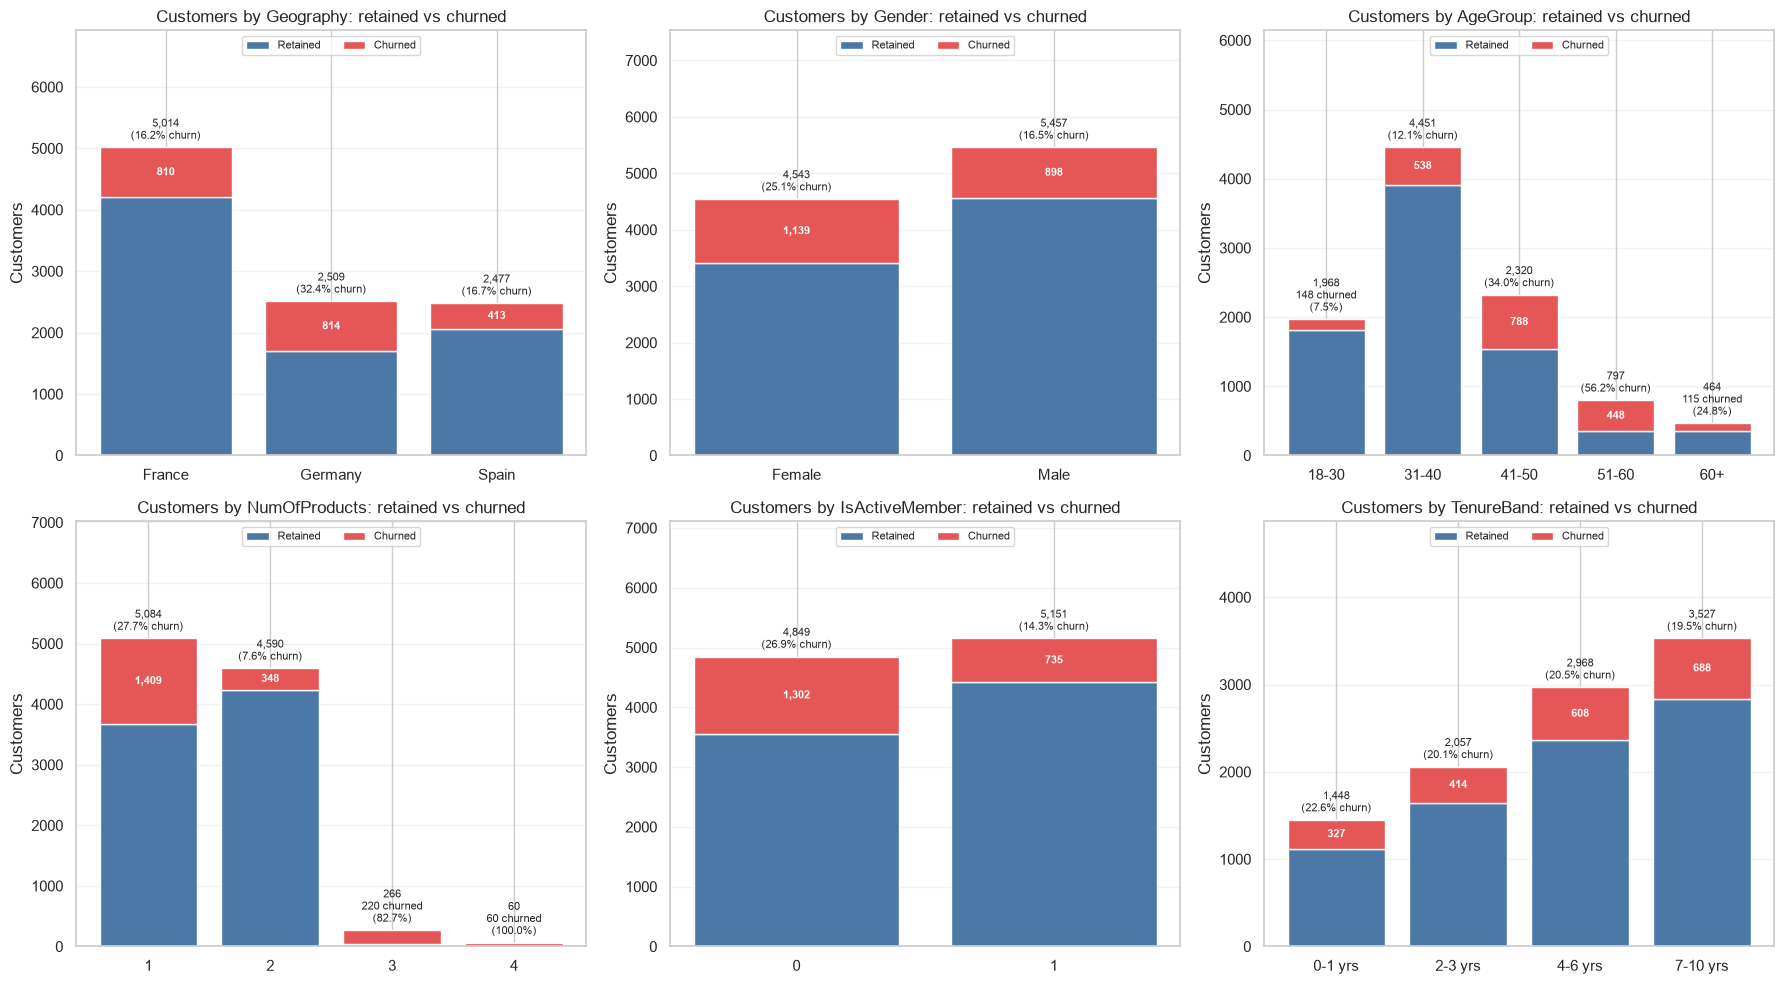

In [9]:

# %% 6b. Stacked bars: retained vs churned customers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("charts", exist_ok=True)

def plot_stacked(col, ax):
    # Validate the required columns
    if col not in df.columns:
        raise KeyError(f"Column '{col}' not found in df")

    if "Exited" not in df.columns:
        raise KeyError("Column 'Exited' not found in df")

    # Exclude missing category and target values
    temp = df[[col, "Exited"]].dropna().copy()

    # Crosstab guarantees both target columns exist
    ct = pd.crosstab(temp[col], temp["Exited"])
    ct = ct.reindex(columns=[0, 1], fill_value=0)
    ct.columns = ["Retained", "Churned"]

    # Keep only categories that have customers
    ct = ct.loc[ct.sum(axis=1) > 0]

    if ct.empty:
        raise ValueError(f"No valid data available for {col}")

    totals = ct["Retained"] + ct["Churned"]
    churn_rate = ct["Churned"].div(totals).mul(100)

    # Plot positions
    x = np.arange(len(ct))
    retained = ct["Retained"].to_numpy()
    churned = ct["Churned"].to_numpy()
    total = totals.to_numpy()

    # Stacked bars
    ax.bar(
        x, retained,
        color="#4C78A8",
        label="Retained"
    )
    ax.bar(
        x, churned,
        bottom=retained,
        color="#E45756",
        label="Churned"
    )

    # Labels: churned count inside the bar when there is enough space
    min_inside = max(total.max() * 0.05, 1)

    for i in range(len(ct)):
        if churned[i] >= min_inside:
            ax.text(
                x[i],
                retained[i] + churned[i] / 2,
                f"{churned[i]:,}",
                ha="center",
                va="center",
                color="white",
                fontsize=8,
                fontweight="bold"
            )
            top_label = (
                f"{total[i]:,}\n"
                f"({churn_rate.iloc[i]:.1f}% churn)"
            )
        else:
            top_label = (
                f"{total[i]:,}\n"
                f"{churned[i]:,} churned\n"
                f"({churn_rate.iloc[i]:.1f}%)"
            )

        ax.annotate(
            top_label,
            xy=(x[i], total[i]),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8
        )

    # Formatting
    ax.set_xticks(x)
    ax.set_xticklabels(ct.index.astype(str))
    ax.set_ylim(0, total.max() * 1.38)
    ax.set_title(f"Customers by {col}: retained vs churned")
    ax.set_ylabel("Customers")
    ax.legend(loc="upper center", ncol=2, fontsize=8)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)


# Six required charts
stack_cols = [
    "Geography",
    "Gender",
    "AgeGroup",
    "NumOfProducts",
    "IsActiveMember",
    "TenureBand"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, col in zip(axes.flat, stack_cols):
    try:
        plot_stacked(col, ax)
    except Exception as e:
        ax.clear()
        ax.set_title(f"Could not plot: {col}")
        ax.text(
            0.5, 0.5,
            f"{type(e).__name__}\n{e}",
            transform=ax.transAxes,
            ha="center",
            va="center",
            wrap=True
        )
        print(f"ERROR in {col}: {type(e).__name__}: {e}")

fig.tight_layout()

fig.savefig(
    "charts/stacked_churn_by_factor.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [12]:

# Correlation of numeric factors with customer churn

import pandas as pd

# Check that the target column exists
if "Exited" not in df.columns:
    raise KeyError(
        f"'Exited' not found. Available columns: {df.columns.tolist()}"
    )

# Select numeric columns and calculate correlations
num = df.select_dtypes(include="number")

if "Exited" not in num.columns:
    raise ValueError("'Exited' must be a numeric column.")

corr_tbl = (
    num.corr(numeric_only=True)["Exited"]
    .drop(labels=["Exited"])
    .reset_index()
)

corr_tbl.columns = ["Factor", "Correlation"]
corr_tbl["Correlation"] = corr_tbl["Correlation"].round(2)

# Save and display results
corr_tbl.to_csv("correlation.csv", index=False)

print(corr_tbl)
print("\nSaved to correlation.csv")


            Factor  Correlation
0        RowNumber        -0.02
1       CustomerId        -0.01
2      CreditScore        -0.03
3              Age         0.29
4           Tenure        -0.01
5          Balance         0.12
6    NumOfProducts        -0.05
7        HasCrCard        -0.01
8   IsActiveMember        -0.16
9  EstimatedSalary         0.01

Saved to correlation.csv


In [14]:
num = df.select_dtypes(include="number").drop(
    columns=["RowNumber", "CustomerId"],
    errors="ignore"
)

corr_tbl = (
    num.corr()["Exited"]
    .drop("Exited")
    .rename_axis("Factor")
    .reset_index(name="Correlation")
)

corr_tbl["Correlation"] = corr_tbl["Correlation"].round(2)

corr_tbl.to_csv("correlation.csv", index=False)

print(corr_tbl)

            Factor  Correlation
0      CreditScore        -0.03
1              Age         0.29
2           Tenure        -0.01
3          Balance         0.12
4    NumOfProducts        -0.05
5        HasCrCard        -0.01
6   IsActiveMember        -0.16
7  EstimatedSalary         0.01


In [19]:
corr_tbl.to_csv("correlation.csv", index=False)

In [21]:
print(df.columns.tolist())

['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'AgeGroup', 'TenureBand']


In [23]:

import numpy as np

df["Pts_Age"] = (df["Age"] >= 50).astype(int) * 3

df["Pts_Germany"] = (df["Geography"] == "Germany").astype(int) * 2

df["Pts_Products"] = (df["NumOfProducts"] >= 3).astype(int) * 3

df["Pts_Inactive"] = (df["IsActiveMember"] == 0).astype(int) * 2

df["Pts_Combo"] = (
    (df["Geography"] == "Germany") &
    (df["Age"].between(41, 60))
).astype(int)

df["RiskScore"] = (
    df["Pts_Age"] +
    df["Pts_Germany"] +
    df["Pts_Products"] +
    df["Pts_Inactive"] +
    df["Pts_Combo"]
)

df[["Age", "Geography", "NumOfProducts",
    "IsActiveMember", "RiskScore"]].head(10)


,Age,Geography,NumOfProducts,IsActiveMember,RiskScore
0,42,France,1,1,0
1,41,Spain,1,1,0
2,42,France,3,0,5
3,39,France,2,0,2
4,43,Spain,1,1,0
5,44,Spain,2,0,2
6,50,France,2,1,3
7,29,Germany,4,0,7
8,44,France,2,1,0
9,27,France,1,1,0


In [25]:

df["RiskTier"] = pd.cut(
    df["RiskScore"],
    bins=[-1, 2, 4, 11],
    labels=["Low", "Medium", "High"]
)

df[["RiskScore", "RiskTier"]].head(10)


,RiskScore,RiskTier
0,0,Low
1,0,Low
2,5,High
3,2,Low
4,0,Low
5,2,Low
6,3,Medium
7,7,High
8,0,Low
9,0,Low


In [26]:

# Remove temporary scoring columns
df.drop(
    columns=[
        "Pts_Age",
        "Pts_Germany",
        "Pts_Products",
        "Pts_Inactive",
        "Pts_Combo"
    ],
    inplace=True
)

# Check risk categories
print(df["RiskTier"].value_counts())

# Export the updated dataset
df.to_csv("bank_churn_clean.csv", index=False)

print("Updated dataset exported successfully!")


RiskTier
Low       7076
Medium    1688
High      1236
Name: count, dtype: int64
Updated dataset exported successfully!
